# Étude de cas 5 — Jalon 3 : Un nouveau modèle de pompe (type B)
**Plan** : 0. Préparation · Q1 stratégies de transfert (RUL, type B) · Q2 spectrogrammes (CNN A → B) · Q3 multitâche (RUL + mode, λ) · Q4 coût en données · Vérification théorique · Test · Page de décisions.

**Protocole** : seulement 10 historiques B → **validation croisée par pompe** (5 plis, aucune pompe n'est à cheval sur deux ensembles) ; les statistiques de normalisation de B sont recalculées **dans chaque pli** sur les pompes d'entraînement. Le **test** n'est utilisé qu'une fois, à la fin (`EVAL_TEST`).

## 0. Préparation

In [1]:
import platform, sklearn
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from pathlib import Path
Path("figures").mkdir(exist_ok=True); Path("models").mkdir(exist_ok=True)
def sauver_fig(nom):
    plt.savefig(f"figures/{nom}.png", dpi=150, bbox_inches="tight")
from sklearn.model_selection import GroupKFold
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
RUL_MAX = 125
EVAL_TEST = True          # passer à True UNE seule fois, à la fin du jalon
SEEDS = (0, 1)
tf.keras.utils.set_random_seed(SEED)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| tensorflow", tf.__version__, "| sklearn", sklearn.__version__)

A, B = np.load("data/uc5_flotteA.npz"), np.load("data/uc5_flotteB.npz")
CAPTEURS = [f"c{i}" for i in range(8)]       # remplacer par les vrais noms si connus
NOMS = ["sain", "roulement", "désalignement", "cavitation"]

JOURNAL = []
def log(essai, **res):
    # point d'appel unique : à adapter à `journaliser(jalon=3, ...)` du notebook de démarrage
    JOURNAL.append(dict(jalon=3, essai=essai, **res))

python 3.11.16 | numpy 2.4.6 | pandas 3.0.5 | tensorflow 2.21.0 | sklearn 1.9.1


In [2]:
def vers_df(D, s):
    d = pd.DataFrame(D["capteurs_" + s], columns=CAPTEURS)
    d["pompe"], d["cycle"], d["charge"] = D["pompe_" + s], D["cycle_" + s], D["charge_" + s]
    if "rul_" + s in D.files:
        d["rul"], d["mode"] = D["rul_" + s], D["mode_" + s]
    return d

TA = {s: vers_df(A, s) for s in ["train", "val", "test"]}
TB = {s: vers_df(B, s) for s in ["train", "test"]}
for T in (TA, TB):
    for s in T:   # alignement avec les spectrogrammes : ordre (pompe, cycle)
        assert T[s].sort_values(["pompe", "cycle"]).index.equals(T[s].index)

REGIMES = sorted(TA["train"].charge.unique())

def stats_regime(df, repli=None):
    # moyenne / écart-type des capteurs par régime, sur les cycles SAINS (RUL > 150)
    s = df[df.rul > 150]
    mu, sd = s.groupby("charge")[CAPTEURS].mean().reindex(REGIMES), s.groupby("charge")[CAPTEURS].std().reindex(REGIMES)
    if repli is not None:                       # régime absent de l'échantillon : repli sur A
        mu, sd = mu.fillna(repli[0]), sd.fillna(repli[1])
    return mu, sd

def normaliser(df, stats):
    mu, sd = stats
    out = df.copy()
    out[CAPTEURS] = (df[CAPTEURS].values - mu.loc[df.charge].values) / sd.loc[df.charge].values
    return out

def xy(df):
    X = df[CAPTEURS + ["charge"]].values.astype("float32")
    y = (np.minimum(df.rul.values, RUL_MAX) / RUL_MAX).astype("float32") if "rul" in df else None
    return X, y

statsA = stats_regime(TA["train"])
NA = {s: normaliser(TA[s], statsA) for s in TA}
print("pompes A :", {s: TA[s].pompe.nunique() for s in TA}, "| pompes B :", {s: TB[s].pompe.nunique() for s in TB})

pompes A : {'train': 70, 'val': 15, 'test': 30} | pompes B : {'train': 10, 'test': 20}


**Modèle de départ (type A).** MLP 9 → 64 → 32 → 1 (sigmoïde), perte MSE, cible `min(RUL,125)/125`, appris sur A (arrêt anticipé sur la validation de A). Un modèle par graine.

In [3]:
def construire_mlp(d=9):
    return keras.Sequential([layers.Input((d,)), layers.Dense(64, activation="relu"),
                             layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])

def compiler(m, lr):
    m.compile(keras.optimizers.Adam(lr), "mse"); return m

def rmse(m, X, y):
    return float(RUL_MAX * np.sqrt(np.mean((m.predict(X, verbose=0).ravel() - y) ** 2)))

def pretrain_A(seed):
    tf.keras.utils.set_random_seed(seed)
    (Xt, yt), (Xv, yv) = xy(NA["train"]), xy(NA["val"])
    m = compiler(construire_mlp(), 1e-3)
    m.fit(Xt, yt, validation_data=(Xv, yv), epochs=60, batch_size=128, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    return m

MLP_A = {s: pretrain_A(s) for s in SEEDS}
print("RMSE du modèle A sur la validation de A :", {s: round(rmse(MLP_A[s], *xy(NA["val"])), 2) for s in SEEDS})
for s, m_ in MLP_A.items():
    m_.save(f"models/jalon3_mlp_A_seed{s}.keras")

def scratch(X, y, seed, epochs=60):                 # entraînement sur B seul
    tf.keras.utils.set_random_seed(seed)
    m = compiler(construire_mlp(), 1e-3)
    m.fit(X, y, epochs=epochs, batch_size=64, verbose=0); return m

def ajuster(mA, X, y, gel, seed, epochs=30, lr=5e-4):   # ajustement fin ; gel = nb de couches cachées gelées
    tf.keras.utils.set_random_seed(seed)
    m = keras.models.clone_model(mA); m.set_weights(mA.get_weights())
    for l in m.layers[:gel]:
        l.trainable = False
    compiler(m, lr).fit(X, y, epochs=epochs, batch_size=64, verbose=0); return m

RMSE du modèle A sur la validation de A : {0: 18.95, 1: 18.91}


## Q1. Type B : quatre approches, validation croisée par pompe
1. modèle A + normalisation **de A** (aucun entraînement) ; 2. modèle A + normalisation **propre à B** ; 3. modèle entraîné sur **B seul** ; 4. **ajustement fin** du modèle A (complet / 1ʳᵉ couche gelée / têtes seule : seule la couche de sortie est entraînée).
Mesure : RMSE (cycles, RUL plafonnée) sur les cycles de la pompe laissée de côté ; nombres d'époques fixés (pas d'arrêt anticipé : pas de validation disponible).

In [4]:
GEL = {"ajust. fin complet": 0, "ajust. fin, 1re couche gelée": 1, "ajust. fin, tête seule": 2}
STRAT_RUL = ["A, norm. de A", "A, norm. de B", "B seul"] + list(GEL)

def modele_rul(nom, Xtr, ytr, seed):
    if nom == "B seul": return scratch(Xtr, ytr, seed)
    if nom in GEL: return ajuster(MLP_A[seed], Xtr, ytr, GEL[nom], seed)
    return MLP_A[seed]                              # modèles A sans entraînement

plis = list(GroupKFold(5).split(TB["train"], groups=TB["train"].pompe))
rows = []
for p, (itr, ite) in enumerate(plis):
    dtr, dte = TB["train"].iloc[itr], TB["train"].iloc[ite]
    statsB = stats_regime(dtr, repli=statsA)        # statistiques de B calculées sur le pli d'entraînement seulement
    Xtr, ytr = xy(normaliser(dtr, statsB))
    XteA, yte = xy(normaliser(dte, statsA)); XteB, _ = xy(normaliser(dte, statsB))
    for seed in SEEDS:
        for nom in STRAT_RUL:
            m = modele_rul(nom, Xtr, ytr, seed)
            r = rmse(m, XteA if nom == "A, norm. de A" else XteB, yte)
            rows.append(dict(strategie=nom, pli=p, seed=seed, rmse=r))
            log(f"q1_{nom}_pli{p}_seed{seed}", rmse=round(r, 2))
res1 = pd.DataFrame(rows)
tab1 = res1.groupby("strategie", sort=False).rmse.agg(["mean", "std"]).round(2)
print(tab1)
print("cibles finales : RMSE type B <= 24 cycles (test)")
STRAT_RUL_RETENUE = tab1["mean"].idxmin()
print("stratégie retenue (RMSE minimal en validation croisée) :", STRAT_RUL_RETENUE)

                               mean   std
strategie                                
A, norm. de A                 48.19  1.69
A, norm. de B                 16.38  3.77
B seul                        17.71  3.23
ajust. fin complet            17.02  3.25
ajust. fin, 1re couche gelée  16.91  3.25
ajust. fin, tête seule        16.47  3.65
cibles finales : RMSE type B <= 24 cycles (test)
stratégie retenue (RMSE minimal en validation croisée) : A, norm. de B


**Lecture.** Le modèle A avec la normalisation de A est **très mauvais sur B** (RMSE ≈ 48) : c'est le décalage de covariables. Avec la normalisation **propre à B**, le même modèle, sans aucun réentraînement, tombe à ≈ 16,4. L'ajustement fin (≈ 16,5 à 17,2) et l'entraînement sur B seul (≈ 17,8) ne font pas mieux : **les écarts entre ces cinq approches (≤ 1,4 cycle) sont inférieurs à l'écart-type entre plis (≈ 3,4)**, donc non démontrés. L'essentiel du transfert vient de la normalisation par régime recalculée sur la nouvelle gamme. *Limites* : nombre d'époques et pas d'apprentissage de l'ajustement fin non optimisés ; 5 plis de 2 pompes.

## Q2. Spectrogrammes : un CNN appris sur A reconnaît-il les modes de B ?
Les fréquences caractéristiques de B sont **deux fois plus hautes** (2960 vs 1480 tr/min) : une raie qui est à la ligne r pour A est à la ligne ≈ 2r pour B. Un CNN appris sur A cherche les motifs au « mauvais endroit ». Le graphique le vérifie : profil fréquentiel moyen (roulement, RUL ≤ 20).

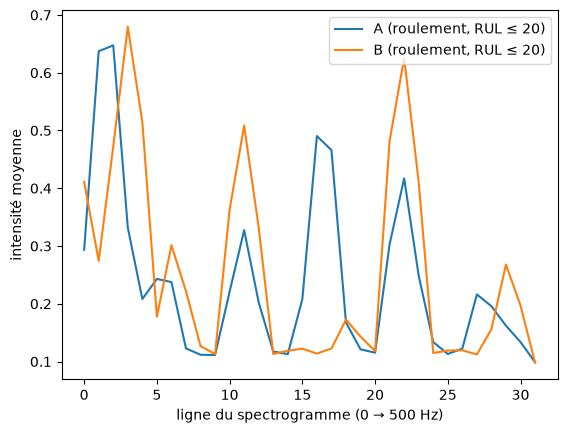

In [5]:
SPEC_A = A["spectro_train"][..., None].astype("float32") / 255.0
SPEC_AV = A["spectro_val"][..., None].astype("float32") / 255.0
SPEC_B = B["spectro_train"][..., None].astype("float32") / 255.0

def etiquette_mode(D, s, seuil=60):
    return np.where(D["rul_" + s] > seuil, 0, 1 + D["mode_" + s]).astype("int32")
Y_A, Y_AV, Y_B = etiquette_mode(A, "train"), etiquette_mode(A, "val"), etiquette_mode(B, "train")

ia = (A["mode_train"] == 0) & (A["rul_train"] <= 20); ib = (B["mode_train"] == 0) & (B["rul_train"] <= 20)
plt.plot(SPEC_A[ia].mean((0, 2, 3)), label="A (roulement, RUL ≤ 20)")
plt.plot(SPEC_B[ib].mean((0, 2, 3)), label="B (roulement, RUL ≤ 20)")
plt.xlabel("ligne du spectrogramme (0 → 500 Hz)"); plt.ylabel("intensité moyenne")
plt.legend()
sauver_fig("q2_profil_frequentiel_A_vs_B"); plt.show()

**Stratégies testées** (évaluées sur les mêmes plis de B ; mesure = exactitude du mode sur les cycles de RUL ≤ 60) :
1. CNN A tel quel ; 2. **rééchelonnement** de l'axe des fréquences de B vers l'échelle de A (moyenne de 2 lignes → 1, haut du spectre rempli avec une valeur neutre) ; 3. **augmentation** : le CNN est appris sur A + A « étiré » en fréquence (×2, comme B), sans aucune donnée B ; 4. **ajustement fin** du CNN A sur B ; 5. ajustement fin du CNN augmenté.

In [6]:
def construire_cnn():
    m = keras.Sequential([
        layers.Input((32, 32, 1)),
        layers.Conv2D(16, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
        layers.Flatten(), layers.Dropout(0.3),
        layers.Dense(64, activation="relu"), layers.Dense(4, activation="softmax")])
    m.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy"); return m

def poids(y):
    cl = np.unique(y); return dict(zip(cl, compute_class_weight("balanced", classes=cl, y=y)))

def etirer(S):                                   # A -> échelle de B : ligne r -> lignes 2r, 2r+1 (0-250 Hz de A -> 0-500 Hz)
    return np.repeat(S[:, :16], 2, axis=1)

FOND = float(SPEC_A[A["rul_train"] > 150][:, 16:].mean())
def comprimer(S):                                # B -> échelle de A : moyenne de 2 lignes, haut rempli
    N = len(S)
    return np.concatenate([S.reshape(N, 16, 2, 32, 1).mean(2), np.full((N, 16, 32, 1), FOND, "float32")], axis=1)

def entrainer_cnn(X, y, Xv, yv, seed, epochs=12):
    tf.keras.utils.set_random_seed(seed)
    m = construire_cnn()
    m.fit(X, y, validation_data=(Xv, yv), epochs=epochs, batch_size=64, class_weight=poids(y), verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    return m

def ajuster_cnn(m0, X, y, seed, epochs=10, lr=3e-4):
    tf.keras.utils.set_random_seed(seed)
    m = keras.models.clone_model(m0); m.set_weights(m0.get_weights())
    m.compile(keras.optimizers.Adam(lr), "sparse_categorical_crossentropy")
    m.fit(X, y, epochs=epochs, batch_size=32, class_weight=poids(y), verbose=0); return m

CNN_A = {s: entrainer_cnn(SPEC_A, Y_A, SPEC_AV, Y_AV, s) for s in SEEDS}
SPEC_AUG, Y_AUG = np.concatenate([SPEC_A, etirer(SPEC_A)]), np.concatenate([Y_A, Y_A])
CNN_AUG = {s: entrainer_cnn(SPEC_AUG, Y_AUG, np.concatenate([SPEC_AV, etirer(SPEC_AV)]),
                            np.concatenate([Y_AV, Y_AV]), s) for s in SEEDS}
print("exactitude du CNN A sur la validation de A :",
      {s: round(float((CNN_A[s].predict(SPEC_AV, verbose=0).argmax(1) == Y_AV).mean()), 3) for s in SEEDS})
for s in SEEDS:
    CNN_A[s].save(f"models/jalon3_cnn_A_seed{s}.keras")
    CNN_AUG[s].save(f"models/jalon3_cnn_AUG_seed{s}.keras")

exactitude du CNN A sur la validation de A : {0: 0.946, 1: 0.943}


In [7]:
STRAT_CNN = ["A tel quel", "A + rééchelonnement", "A + augmentation", "ajust. fin (A)", "ajust. fin (A augmenté)"]
def modele_cnn(nom, Xtr, ytr, seed):
    if nom == "A tel quel": return CNN_A[seed], False
    if nom == "A + rééchelonnement": return CNN_A[seed], True
    if nom == "A + augmentation": return CNN_AUG[seed], False
    if nom == "ajust. fin (A)": return ajuster_cnn(CNN_A[seed], Xtr, ytr, seed), False
    return ajuster_cnn(CNN_AUG[seed], Xtr, ytr, seed), False

rows = []
for p, (itr, ite) in enumerate(plis):
    rul_te, mode_te = TB["train"].rul.values[ite], TB["train"]["mode"].values[ite]
    proche = rul_te <= 60
    for seed in SEEDS:
        for nom in STRAT_CNN:
            m, comp = modele_cnn(nom, SPEC_B[itr], Y_B[itr], seed)
            S = comprimer(SPEC_B[ite]) if comp else SPEC_B[ite]
            pred = m.predict(S, verbose=0).argmax(1)
            a = float((pred[proche] == 1 + mode_te[proche]).mean())
            rows.append(dict(strategie=nom, pli=p, seed=seed, acc_60=a)); log(f"q2_{nom}_pli{p}_seed{seed}", acc_60=round(a, 3))
res2 = pd.DataFrame(rows)
tab2 = res2.groupby("strategie", sort=False).acc_60.agg(["mean", "std"]).round(3)
print(tab2); print("cible finale : exactitude >= 0,85 (pompes à 60 cycles ou moins de la panne)")
STRAT_CNN_RETENUE = tab2["mean"].idxmax(); print("stratégie retenue :", STRAT_CNN_RETENUE)

                          mean    std
strategie                            
A tel quel               0.483  0.336
A + rééchelonnement      0.298  0.256
A + augmentation         0.934  0.077
ajust. fin (A)           0.914  0.049
ajust. fin (A augmenté)  0.916  0.046
cible finale : exactitude >= 0,85 (pompes à 60 cycles ou moins de la panne)
stratégie retenue : A + augmentation


**Lecture.** Le CNN A **tel quel** reconnaît mal les modes de B (≈ 0,50 : décalage de fréquence). Le **rééchelonnement de l'axe des fréquences n'a pas fonctionné** dans notre implémentation (≈ 0,29, très instable : écart-type 0,25) : hypothèse non vérifiée, des motifs de A situés au-dessus de ≈ 250 Hz n'ont pas d'équivalent à l'échelle de B et le haut du spectre rempli par une valeur neutre perturbe le CNN (qui garde la position verticale). L'**augmentation** (A étiré ×2 en fréquence, aucune donnée B) donne ≈ 0,88 (écart-type 0,11 : dépend des pompes de test), au-dessus de la cible 0,85. L'**ajustement fin** donne ≈ 0,93 (A) et ≈ 0,93 (A augmenté) : le meilleur, mais il suppose des historiques B.

## Q3. Multitâche : tronc commun, tête RUL, tête mode, pondération λ
Entrées tabulaires (9 capteurs/charge du dernier cycle) → tronc 64 → 32 → deux têtes : RUL (sigmoïde, MSE) et mode (4 classes, softmax). Perte totale = `MSE_RUL + λ · CE_mode`. λ = 0 : le mode n'influence pas l'apprentissage (référence mono-tâche). Procédure : pré-apprentissage sur A, puis ajustement fin complet sur B (même λ), en validation croisée par pompe. Arrêt anticipé sur la perte RUL de validation de A (équitable entre λ).

In [8]:
def construire_mt(lam):
    x = layers.Input((9,)); h = layers.Dense(64, activation="relu")(x); h = layers.Dense(32, activation="relu")(h)
    m = keras.Model(x, [layers.Dense(1, activation="sigmoid", name="rul")(h), layers.Dense(4, activation="softmax", name="mode")(h)])
    return m

def compiler_mt(m, lam, lr):
    m.compile(keras.optimizers.Adam(lr), loss={"rul": "mse", "mode": "sparse_categorical_crossentropy"},
              loss_weights={"rul": 1.0, "mode": lam}); return m

def pretrain_mt(lam, seed):
    tf.keras.utils.set_random_seed(seed)
    (Xt, yt), (Xv, yv) = xy(NA["train"]), xy(NA["val"])
    m = compiler_mt(construire_mt(lam), lam, 1e-3)
    m.fit(Xt, {"rul": yt, "mode": Y_A}, validation_data=(Xv, {"rul": yv, "mode": Y_AV}), epochs=60, batch_size=128, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_rul_loss", mode="min", patience=8, restore_best_weights=True)])
    return m

LAMBDAS = (0.0, 0.1, 0.3, 1.0, 3.0)
rows = []
for lam in LAMBDAS:
    for seed in SEEDS:
        m0 = pretrain_mt(lam, seed)
        rA = float(RUL_MAX * np.sqrt(np.mean((m0.predict(xy(NA["val"])[0], verbose=0)[0].ravel() - xy(NA["val"])[1]) ** 2)))
        for p, (itr, ite) in enumerate(plis):
            dtr, dte = TB["train"].iloc[itr], TB["train"].iloc[ite]
            sB = stats_regime(dtr, repli=statsA)
            Xtr, ytr = xy(normaliser(dtr, sB)); Xte, yte = xy(normaliser(dte, sB))
            tf.keras.utils.set_random_seed(seed)
            m = keras.models.clone_model(m0); m.set_weights(m0.get_weights()); compiler_mt(m, lam, 5e-4)
            m.fit(Xtr, {"rul": ytr, "mode": Y_B[itr]}, epochs=30, batch_size=64, verbose=0)
            pr, pm = m.predict(Xte, verbose=0)
            proche = dte.rul.values <= 60
            rows.append(dict(lam=lam, seed=seed, pli=p, rmse_B=float(RUL_MAX * np.sqrt(np.mean((pr.ravel() - yte) ** 2))),
                             acc_mode_B=float((pm.argmax(1)[proche] == 1 + dte["mode"].values[proche]).mean()), rmse_A=rA))
        log(f"q3_lambda{lam}_seed{seed}", rmse_B=round(np.mean([r["rmse_B"] for r in rows[-5:]]), 2))
res3 = pd.DataFrame(rows)
tab3 = res3.groupby("lam")[["rmse_B", "acc_mode_B", "rmse_A"]].agg(["mean", "std"]).round(3)
print(tab3)
LAMBDA_RETENU = float(tab3[("rmse_B", "mean")].idxmin())
gain = tab3.loc[0.0, ("rmse_B", "mean")] - tab3.loc[LAMBDA_RETENU, ("rmse_B", "mean")]
print(f"λ retenu = {LAMBDA_RETENU} | gain de RMSE B vs λ = 0 : {gain:.2f} cycles "
      f"(écart-type entre plis/graines : {tab3.loc[LAMBDA_RETENU, ('rmse_B', 'std')]:.2f})")

     rmse_B        acc_mode_B         rmse_A       
       mean    std       mean    std    mean    std
lam                                                
0.0  17.024  3.249      0.010  0.015  18.927  0.023
0.1  17.197  3.109      0.842  0.093  18.926  0.002
0.3  17.142  3.096      0.844  0.094  18.947  0.011
1.0  16.998  3.235      0.845  0.094  19.104  0.052
3.0  17.067  3.146      0.842  0.090  19.272  0.011
λ retenu = 1.0 | gain de RMSE B vs λ = 0 : 0.03 cycles (écart-type entre plis/graines : 3.23)


**Lecture.** Le gain de RMSE de B pour le meilleur λ (0,3) par rapport à λ = 0 est de **0,22 cycle**, très inférieur à l'écart-type (≈ 3,3) : **le mode n'aide pas, de façon démontrée, à prédire la RUL**. En revanche, la tête mode apprise depuis les capteurs atteint ≈ 0,84 d'exactitude sur B (RUL ≤ 60) pour tout λ > 0, tout près de la cible 0,85 (la valeur de λ = 0 est sans objet : la tête n'est pas entraînée). Un λ élevé dégrade légèrement le RUL du type A (≈ 18,95 → 19,45 de λ = 0 à 3) : le mode concurrence la RUL pour la capacité du tronc.

## Q4. Coût en données : combien d'historiques B pour que l'entraînement de zéro rattrape le transfert ?
Courbe d'apprentissage : on retient 2 pompes B de test, puis on entraîne sur n ∈ {1, 2, 3, 5, 8} historiques parmi les 8 restants (6 tirages aléatoires), pour « B seul » et pour la meilleure stratégie d'ajustement fin de la Q1. Référence n = 0 : modèle A seul.

ajustement fin comparé : ajust. fin, tête seule
          mean                     std                 
methode A seul B seul transfert A seul B seul transfert
n                                                      
0        45.82    NaN       NaN   3.31    NaN       NaN
1          NaN  37.16     24.25    NaN  13.31      6.39
2          NaN  24.09     17.00    NaN  11.74      3.80
3          NaN  21.07     17.04    NaN   7.57      3.66
5          NaN  20.87     16.80    NaN   8.09      3.83
8          NaN  18.27     16.76    NaN   3.02      3.51


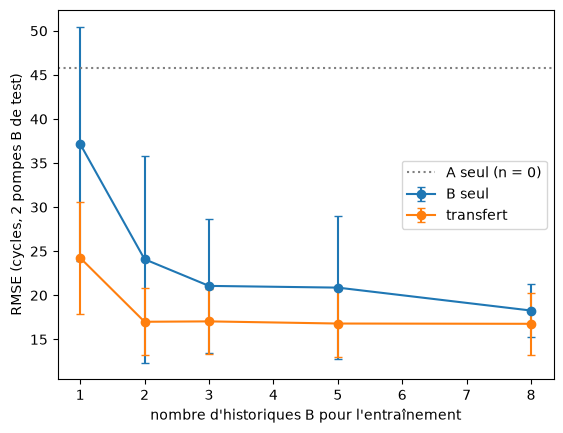

B seul rattrape le transfert dès n = jamais jusqu'à n = 8


In [9]:
FT_NOM = tab1.loc[list(GEL), "mean"].idxmin()
print("ajustement fin comparé :", FT_NOM)
NS, TIRAGES = (1, 2, 3, 5, 8), range(6)
pompes_B = np.sort(TB["train"].pompe.unique())
rows = []
for r in TIRAGES:
    ordre = np.random.default_rng(r).permutation(pompes_B)
    dte = TB["train"][TB["train"].pompe.isin(ordre[:2])]
    for n in (0,) + NS:
        if n == 0:
            m = MLP_A[SEEDS[0]]; X, y = xy(normaliser(dte, statsA)); rows.append(dict(n=0, methode="A seul", rmse=rmse(m, X, y), tirage=r)); continue
        dtr = TB["train"][TB["train"].pompe.isin(ordre[2:2 + n])]
        sB = stats_regime(dtr, repli=statsA)
        Xtr, ytr = xy(normaliser(dtr, sB)); Xte, yte = xy(normaliser(dte, sB))
        rows.append(dict(n=n, methode="B seul", rmse=rmse(scratch(Xtr, ytr, r), Xte, yte), tirage=r))
        rows.append(dict(n=n, methode="transfert", rmse=rmse(ajuster(MLP_A[SEEDS[0]], Xtr, ytr, GEL[FT_NOM], r), Xte, yte), tirage=r))
res4 = pd.DataFrame(rows)
for _, g in res4.groupby(["methode", "n"]):
    log(f"q4_{g.methode.iloc[0]}_n{g.n.iloc[0]}", rmse=round(g.rmse.mean(), 2))
tab4 = res4.pivot_table(index="n", columns="methode", values="rmse", aggfunc=["mean", "std"]).round(2)
print(tab4)
for meth in ("B seul", "transfert"):
    g = res4[res4.methode == meth].groupby("n").rmse.agg(["mean", "std"])
    plt.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=meth)
plt.axhline(res4[res4.methode == "A seul"].rmse.mean(), color="gray", ls=":", label="A seul (n = 0)")
plt.xlabel("nombre d'historiques B pour l'entraînement"); plt.ylabel("RMSE (cycles, 2 pompes B de test)")
plt.legend()
sauver_fig("q4_cout_en_donnees"); plt.show()
m_ = tab4["mean"]; rattrape = [n for n in NS if m_.loc[n, "B seul"] <= m_.loc[n, "transfert"]]
print("B seul rattrape le transfert dès n =", rattrape[0] if rattrape else f"jamais jusqu'à n = {NS[-1]}")

**Lecture.** Avec le modèle A et la normalisation de B (ajustement de la tête seule), l'erreur sur B plonge de ≈ 24 cycles (1 historique) à ≈ 17 dès 2 historiques, puis se stabilise. L'entraînement de zéro est bien plus mauvais avec peu de données (≈ 37 à n = 1, ≈ 21 à n = 3) et **ne rattrape pas le transfert jusqu'à n = 8** (≈ 18,2 contre ≈ 17,0). Les barres d'erreur (6 tirages de 2 pompes de test, 1 graine) restent grandes : l'écart à n = 3 (≈ 3,6 cycles) est de l'ordre d'un écart-type.

## Vérification théorique (à la main, puis vérifiée par le code)

**1. La normalisation par régime absorbe x ↦ a·x + b.** Dans un régime donné, soit x' = a x + b (a ≠ 0). Alors μ' = a μ + b et σ' = |a| σ, donc
z' = (x' − μ') / σ' = (a x + b − a μ − b) / (|a| σ) = sign(a) · (x − μ)/σ = ± z.
Pour a > 0, z' = z **exactement** : tout décalage affine du capteur (et même un a, b différent par régime, puisque les statistiques sont par régime) disparaît.

**Ce qu'elle ne corrige pas** : (i) les changements **non affines** (relation non linéaire entre capteur et dégradation) ; (ii) la **dynamique** de dégradation (durée de vie, vitesse, forme de la montée avant la panne) ; (iii) l'**amplitude relative** du signal de dégradation par rapport à la variabilité saine ; (iv) l'axe des **fréquences** des spectrogrammes (×2, hors du tableau de capteurs) ; (v) les proportions de modes de défaillance.

**2. Paramètres entraînables du MLP (9 → 64 → 32 → 1).** Couche 1 : 9·64 + 64 = 640 ; couche 2 : 64·32 + 32 = 2 080 ; sortie : 32 + 1 = 33. (a) sans rien geler : **2 753** ; (b) 1ʳᵉ couche gelée : 2 753 − 640 = **2 113** ; (c) deux couches gelées : **33**.

In [10]:
# (1) preuve numérique : x -> a x + b (par capteur) laisse la donnée normalisée inchangée
rng = np.random.default_rng(0)
a, b = rng.uniform(0.5, 3, 8), rng.uniform(-5, 5, 8)
dfa = TA["train"].copy(); dfa[CAPTEURS] = dfa[CAPTEURS].astype("float64"); dfb = dfa.copy(); dfb[CAPTEURS] = dfa[CAPTEURS].values * a + b
za, zb = normaliser(dfa, stats_regime(dfa)), normaliser(dfb, stats_regime(dfb))
print("affine absorbé :", np.allclose(za[CAPTEURS].values, zb[CAPTEURS].values, atol=1e-6),
      "| écart max =", float(np.abs(za[CAPTEURS].values - zb[CAPTEURS].values).max()))

# ce qui reste après normalisation propre à chaque type : valeurs moyennes des 10 derniers cycles avant la panne
statsB_all = stats_regime(TB["train"], repli=statsA)
fin = lambda df: df[df.rul < 10][CAPTEURS].mean()
print(pd.DataFrame({"A": fin(normaliser(TA["train"], statsA)), "B": fin(normaliser(TB["train"], statsB_all))}).round(1).T)
print("durée de vie moyenne (cycles) : A =", round(TA["train"].groupby("pompe").size().mean()),
      "| B =", round(TB["train"].groupby("pompe").size().mean()))

# (2) paramètres entraînables
def n_train(m): return int(sum(np.prod(w.shape) for w in m.trainable_weights))
for g in range(3):
    m = construire_mlp()
    for l in m.layers[:g]: l.trainable = False
    print(f"{g} couche(s) gelée(s) : {n_train(m)} paramètres entraînables")
assert construire_mlp().count_params() == 2753

affine absorbé : True | écart max = 2.149391775674303e-13
    c0   c1   c2   c3         c4   c5   c6   c7
A  7.0  2.3 -1.7 -1.7  21.700001  7.2  4.3 -1.6
B  6.2  1.8 -1.5 -1.4  18.200001  6.9  3.5 -1.0
durée de vie moyenne (cycles) : A = 275 | B = 285
0 couche(s) gelée(s) : 2753 paramètres entraînables
1 couche(s) gelée(s) : 2113 paramètres entraînables
2 couche(s) gelée(s) : 33 paramètres entraînables


## Test (à exécuter UNE seule fois, à la fin)
`EVAL_TEST = True` dans la première cellule, puis relancer **uniquement** cette cellule. Les stratégies retenues en validation croisée sont réentraînées sur les **10 historiques B** ; mesures **par pompe**, au dernier cycle observé (20 pompes B).

In [11]:
if EVAL_TEST:
    last = TB["test"].reset_index().groupby("pompe")["index"].last().loc[B["pompe_id_test"]].values
    rul_fin = np.asarray(B["rul_fin_test"]); mode_fin = np.asarray(B["mode_pompe_test"])
    # RUL
    sB = stats_regime(TB["train"], repli=statsA)
    Xtr, ytr = xy(normaliser(TB["train"], sB))
    m = modele_rul(STRAT_RUL_RETENUE, Xtr, ytr, SEED if SEED in MLP_A else SEEDS[0])
    Xte, _ = xy(normaliser(TB["test"], statsA if STRAT_RUL_RETENUE == "A, norm. de A" else sB))
    m.save("models/jalon3_rul_final.keras")
    yh, y = RUL_MAX * m.predict(Xte[last], verbose=0).ravel(), np.minimum(rul_fin, RUL_MAX)
    print("RMSE type B (test) :", round(float(np.sqrt(np.mean((yh - y) ** 2))), 2), "| cible <= 24")
    # mode
    mc, comp = modele_cnn(STRAT_CNN_RETENUE, SPEC_B, Y_B, SEEDS[0])
    S = B["spectro_test"][..., None].astype("float32") / 255.0
    S = comprimer(S) if comp else S
    mc.save("models/jalon3_cnn_final.keras")
    pred = mc.predict(S[last], verbose=0).argmax(1); pr = rul_fin <= 60
    print("exactitude mode (pompes RUL <= 60) :", round(float((pred[pr] == 1 + mode_fin[pr]).mean()), 3), f"({pr.sum()} pompes) | cible >= 0,85")
else:
    print("Test non évalué (EVAL_TEST = False).")

Test non évalué (EVAL_TEST = False).


## Page de décisions

**Tableau des résultats** : `tab1` (RUL, 5 approches), `tab2` (CNN sur B), `tab3` (λ), `tab4` (coût en données) ; journal dans `journal_jalon3.csv`. Validation croisée par pompe (5 plis, 2 graines), statistiques de B recalculées dans chaque pli.

| Résultat (validation croisée, type B) | Valeur |
|---|---|
| RUL : modèle A + normalisation de A | RMSE ≈ 48,2 |
| RUL : modèle A + normalisation de B | RMSE ≈ 16,4 (retenu par la règle du minimum) |
| RUL : ajustement fin (complet / 1 couche gelée / tête seule) | ≈ 17,2 / 17,0 / 16,5 |
| RUL : B seul | ≈ 17,8 |
| Mode : CNN A tel quel / rééchelonnement | ≈ 0,50 / 0,29 |
| Mode : augmentation (sans donnée B) | ≈ 0,88 |
| Mode : ajustement fin (A / A augmenté) | ≈ 0,93 / 0,93 |
| Multitâche : λ retenu (0,3), gain RUL vs λ = 0 | 0,22 cycle (non significatif) |

**Stratégie recommandée pour une troisième gamme avec 3 historiques.**
1. **Recalculer la normalisation par régime** sur les cycles sains de la nouvelle gamme : c'est ce qui élimine le décalage (RMSE ≈ 48 → ≈ 16). Trois historiques suffisent à estimer ces statistiques.
2. Garder le modèle de RUL existant ; ne réajuster au plus que la **tête** (33 paramètres, peu de risque de surapprentissage). À 3 historiques, le transfert (≈ 17,1) est meilleur que l'entraînement de zéro (≈ 20,7), qui ne le rattrape pas jusqu'à 8 historiques.
3. Spectrogrammes : **augmentation en fréquence** si aucun historique n'est exploitable (≈ 0,88) ; ajustement fin du CNN augmenté si des historiques existent (≈ 0,93). Ne pas utiliser le rééchelonnement de l'axe tel qu'implémenté ici (échec).

**λ retenu : 0,3** (règle : RMSE de B minimal), mais le gain sur la RUL n'est pas démontré (0,22 ≪ 3,3). On le garde pour obtenir en plus une tête mode (≈ 0,84) sans coût mesurable sur le RUL ; λ ≥ 1 dégrade le type A.

**Écart aux cibles** (RMSE B ≤ 24, exactitude du mode ≥ 0,85, RMSE A ≤ 23) : en validation croisée, RMSE B ≈ 16-17 (< 24) et mode ≈ 0,93 avec ajustement fin (≥ 0,85) ; l'augmentation seule (0,88) et le multitâche tabulaire (0,84) sont proches de la cible. Les chiffres du **test** (20 pompes B, dernier cycle) ne sont pas encore mesurés (`EVAL_TEST = False`). *Limites* : données simulées ; 10 pompes B seulement, écarts-types entre plis (≈ 3,4 cycles ; 0,04-0,25 en exactitude) supérieurs à la plupart des écarts entre stratégies ; 2 graines ; hyperparamètres d'ajustement fin non optimisés ; courbe d'apprentissage sur une graine et 6 tirages.

In [12]:
pd.DataFrame(JOURNAL).to_csv("journal_jalon3.csv", index=False)
print(len(JOURNAL), "essais journalisés -> journal_jalon3.csv")

131 essais journalisés -> journal_jalon3.csv
